# 股票因子研究：从一句假设走到可审计结果

这是给“懂一点 Python / 机器学习，但第一次研究股票因子”的自主学习实验。没有固定学时，完成一次实验比赶进度更重要。

**本 Notebook 全部使用教学模拟数据，不是真实 A 股，也不是可交易业绩。** 固定一个最简单的假设：过去 5 个交易日跌得更多的股票，未来 5 个交易日会不会反弹？

本次已执行结果：留出样本的平均每日 Rank IC 约 **−0.0928**；Q5 最终净值约 **0.7059**，等权样本约 **0.8319**。假设没有获得这份模拟数据的支持。不要为了让曲线变好而更换种子，也不要看完留出后翻转因子并把同一段结果称为“新验证”。

阅读顺序：每一步先写下“预测”，再运行“操作”，最后回答“观察与练习”。图内使用英文标签避免缺失中文字体；所有解释和练习使用中文。

## 目标与准备

完成以后，你应能回答：一行数据代表什么；因子在哪一刻形成；收益从哪一刻开始算；每日 IC 与非重叠组合为何不同；怎样避免未来信息；费用为什么要在仓位漂移之后计算。

本机内核选择 **Python（因子研究学习）**。依赖与数据契约见同目录 `README.md`。所有计算离线执行，不需要账号或 token。

### 0．导入与固定参数

**预测：** “持有 5 天”是否自动等于“本周一买、下周一卖”？先写出你理解的两个交易时点。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display
from lab import (load_panel, make_synthetic_panel, reversal_factor, standardize_factor,
                 neutralize_factor, forward_returns, time_splits, sample_dates,
                 daily_rank_ic, summarize_ic, assign_groups, backtest_groups,
                 trade_to_target, save_demo_outputs)

ROOT = Path.cwd()
assert (ROOT / 'lab.py').exists(), '请在本 Notebook 所在目录运行。'
SEED, LOOKBACK, H, FEE = 573, 5, 5, 0.001
plt.rcParams.update({'figure.figsize': (10, 4.6), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.18, 'figure.dpi': 120})
pd.set_option('display.max_rows', 12)
pd.set_option('display.max_columns', 10)
print('固定设置：回看5交易日，下一开盘入场，持有5交易日，单边费率10基点。')

固定设置：回看5交易日，下一开盘入场，持有5交易日，单边费率10基点。


## 操作步骤

### 1．先识别“面板”，再算因子

**预测：** 600 个日期、50 只股票，应有多少行？如果某只股票停牌缺了一行，下一行能不能被当成“下一交易日”？

这里生成的是虚构股票 `SIM000` 等，行业与规模也是假设值。日历只去掉周末，不含真实交易所节假日。模拟拆股由复权因子处理。

In [2]:
raw_data, sessions = make_synthetic_panel(n_sessions=600, n_assets=50, seed=SEED)
panel = load_panel(raw_data, sessions=sessions)
display(raw_data.head(6))
display(pd.Series(panel.quality, name='检查结果').to_frame())
assert len(raw_data) == 600 * 50
print('长表的一行是一个日期、一只股票；wide()才转成日期×股票矩阵。')

,date,asset,open,close,adj_factor,amount,industry,log_mv
0,2022-01-03,SIM000,82.867086,83.137073,1.0,2.545986e+07,模拟行业1,23.616097
1,2022-01-03,SIM001,68.173286,66.632077,1.0,2.691472e+07,模拟行业2,22.718282
2,2022-01-03,SIM002,35.067574,35.212340,1.0,1.511394e+07,模拟行业3,24.214184
3,2022-01-03,SIM003,46.630294,45.908572,1.0,1.515317e+07,模拟行业4,22.744023
4,2022-01-03,SIM004,25.872752,25.854807,1.0,6.596714e+07,模拟行业5,22.354556
5,2022-01-03,SIM005,32.080829,32.309049,1.0,1.700936e+07,模拟行业1,22.981625


,检查结果
observed_rows,30000
expected_grid_rows,30000
missing_grid_rows,0
missing_open_cells,0
missing_close_cells,0
n_sessions,600
n_assets,50
already_adjusted,False
price_rule,原价格乘 adj_factor


长表的一行是一个日期、一只股票；wide()才转成日期×股票矩阵。


**观察：** 30,000 行只说明网格完整，不说明它是可信市场数据。每个字段还需要解释来源、单位、历史时点和复权口径。

**练习：** 分别查看 `panel.wide('open').shape` 和 `panel.wide('close').iloc[:3, :4]`。解释为什么“沿日期轴移动”能防止股票之间串线。

### 2．用一只股票手算时间对齐

信号在 $t$ 日收盘后形成。下一交易日 $t+1$ 开盘买入，$t+1+H$ 开盘退出：

$$r_{i,t}^{(H)}=\frac{O_{i,t+1+H}}{O_{i,t+1}}-1.$$

$H=5$ 是两次开盘之间相隔 5 个交易日，不保证对应自然周。同日收盘信号不能按同日开盘价成交。

**预测：** 若信号位于第 10 行，入场和出场分别位于第几行？

In [3]:
signal_pos = 10
asset = 'SIM000'
opens = panel.wide('open')
labels = forward_returns(panel, horizon=H)
timeline = pd.DataFrame({
    '事件': ['形成信号（收盘后）', '入场（开盘）', '出场（开盘）'],
    '日期': [sessions[signal_pos], sessions[signal_pos+1], sessions[signal_pos+1+H]],
    '开盘价（信号行只供定位）': [opens.iloc[signal_pos][asset], opens.iloc[signal_pos+1][asset], opens.iloc[signal_pos+1+H][asset]]})
display(timeline)
manual_return = opens.iloc[signal_pos+1+H][asset] / opens.iloc[signal_pos+1][asset] - 1
print(f'手算标签：{manual_return:.6%}；函数标签：{labels.iloc[signal_pos][asset]:.6%}')
assert np.isclose(manual_return, labels.iloc[signal_pos][asset])

,事件,日期,开盘价（信号行只供定位）
0,形成信号（收盘后）,2022-01-17,77.474066
1,入场（开盘）,2022-01-18,78.443309
2,出场（开盘）,2022-01-25,78.193318


手算标签：-0.318690%；函数标签：-0.318690%


**观察与练习：** 最后 $H+1$ 个信号日为什么没有完整标签？把上面的 `signal_pos` 改成 20，再手算一次。只改变定位，不改变研究参数。

### 3．把“跌得多”写成一个数

$$f_{i,t}^{raw}=-\left(\frac{C_{i,t}}{C_{i,t-5}}-1\right).$$

过去涨 10% 得到 −0.10；过去跌 10% 得到 +0.10。因此因子越高，过去跌得越多。它是一条排序信息，不是预测收益的百分数。

逐日截面先用 1%/99% 分位数缩尾，再用总体标准差 `ddof=0` 做 zscore。所有参数来自**当日截面**，不从未来日期估计。完整 6 个收盘价缺一个，本例就不计算该股票的信号。

**预测：** zscore 后均值应接近多少？标准差应接近多少？缩尾与标准化会自动让因子有效吗？

,过去5日收益,原始反转因子,缩尾并标准化
asset,,,
SIM019,-0.11355,0.11355,2.77029
SIM049,-0.08131,0.08131,2.27388
SIM021,-0.06792,0.06792,1.86965
SIM020,-0.05121,0.05121,1.36531
SIM038,-0.05120,0.05120,1.36484
SIM040,-0.04670,0.04670,1.22911
SIM017,-0.04369,0.04369,1.13810
SIM026,-0.04360,0.04360,1.13547


当日均值 0.000000000000，总体标准差 1.000000


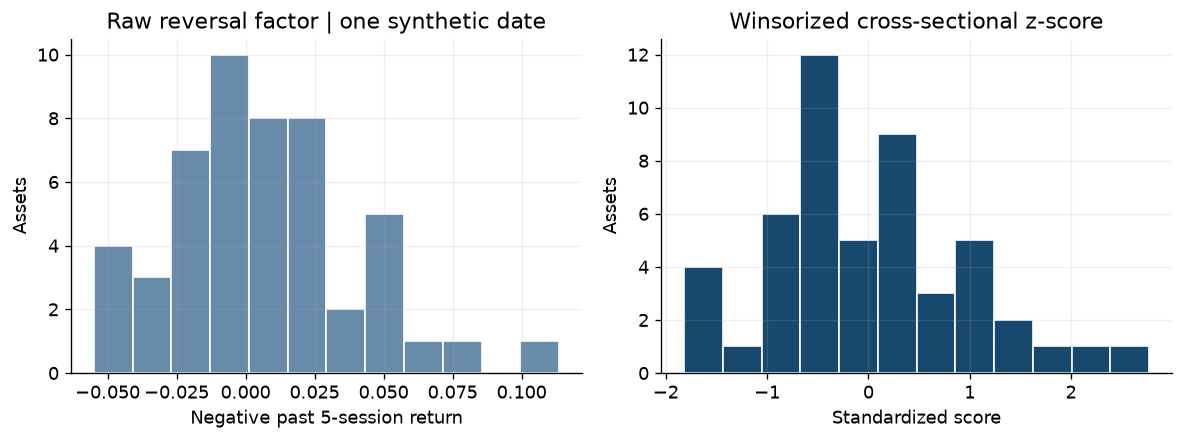

In [4]:
raw_factor = reversal_factor(panel, lookback=LOOKBACK)
score = standardize_factor(raw_factor, lower=0.01, upper=0.99)
day = sessions[300]
example = pd.DataFrame({'过去5日收益': -raw_factor.loc[day],
                        '原始反转因子': raw_factor.loc[day],
                        '缩尾并标准化': score.loc[day]}).sort_values('缩尾并标准化', ascending=False)
display(example.head(8).round(5))
print(f'当日均值 {score.loc[day].mean():.12f}，总体标准差 {score.loc[day].std(ddof=0):.6f}')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(raw_factor.loc[day].dropna(), bins=12, color='#688baa', edgecolor='white')
axes[0].set(title='Raw reversal factor | one synthetic date', xlabel='Negative past 5-session return', ylabel='Assets')
axes[1].hist(score.loc[day].dropna(), bins=12, color='#16496d', edgecolor='white')
axes[1].set(title='Winsorized cross-sectional z-score', xlabel='Standardized score', ylabel='Assets')
fig.tight_layout(); plt.show()

**观察：** 标准化改变尺度，不创造预测能力。分位数缩尾会产生少量并列值，Rank IC 对这些股票使用平均名次。

**练习：** 不运行回测，先口头判断 `score` 最高的股票应该进入 Q1 还是 Q5，并说明理由。

### 4．可选：看看因子是否夹带行业与规模

本步用**模拟历史行业与规模**演示逐日截面回归：因子 = 截距 + 行业虚拟变量 + `log_mv` + 残差，再标准化残差。真实行业缺失时应该跳过，不能伪造，也不能把当前行业回填历史。

这是简单风格控制，不是 Barra。中性化可能去掉混杂暴露，也可能去掉经济假设本身的一部分，所以它是研究选择。

**预测：** 回归残差与当日规模的线性协方差应接近多少？

In [5]:
neutral_score = neutralize_factor(score, panel)
sizes = panel.wide('log_mv').loc[day]
industries = panel.wide('industry').loc[day]
style_comparison = pd.DataFrame({'原因子': score.loc[day], '中性化因子': neutral_score.loc[day],
                                'log_mv': sizes, '行业': industries})
display(style_comparison.groupby('行业')[['原因子', '中性化因子']].mean().round(6))
print('原因子与规模相关：', round(style_comparison['原因子'].corr(style_comparison['log_mv']), 6))
print('中性化后与规模相关：', round(style_comparison['中性化因子'].corr(style_comparison['log_mv']), 6))
print('主线继续使用原因子；本步骤没有根据留出收益选择变体。')

,原因子,中性化因子
行业,,
模拟行业1,0.483192,0.0
模拟行业2,0.005950,-0.0
模拟行业3,-0.502270,-0.0
模拟行业4,-0.211298,-0.0
模拟行业5,0.224427,-0.0


原因子与规模相关： -0.143229
中性化后与规模相关： -0.0
主线继续使用原因子；本步骤没有根据留出收益选择变体。


**练习：** 打开 `lab.py` 的 `neutralize_factor`，找出行业缺失时抛出的错误。解释为什么“先用今天行业给所有历史日期填满”会改变研究含义。

### 5．按日期切样本，并剔除跨界标签

训练/验证/最终留出按交易日 60%/20%/20% 划分。信号日、入场日和出场日必须在同一区间。训练最后几天的未来收益如果跨到验证区间，不能继续留在训练标签中。

验证首日用到此前已经发生的 5 日价格是允许的。这里没有预测模型需要拟合，切分仍然有用：它约束你在何处提出假设、检查实现、做最终评价。

**预测：** H=5 时，若区间末日是第 359 个位置，最后可保留信号应在哪个位置？

In [6]:
splits = time_splits(sessions)
split_rows = []
for name, (start, end) in splits.items():
    dates = sample_dates(sessions, start, end, horizon=H)
    split_rows.append({'样本段': name, '日历起点': start.date(), '日历终点': end.date(),
                       '可完整标签日数（含预热空因子日）': len(dates),
                       '最后保留信号': dates[-1].date(),
                       '对应出场': sessions[sessions.get_loc(dates[-1])+1+H].date()})
display(pd.DataFrame(split_rows))
train_dates = sample_dates(sessions, *splits['训练'], horizon=H)
assert sessions[sessions.get_loc(train_dates[-1])+1+H] <= splits['训练'][1]
assert sessions[sessions.get_loc(train_dates[-1])+2+H] > splits['训练'][1]

,样本段,日历起点,日历终点,可完整标签日数（含预热空因子日）,最后保留信号,对应出场
0,训练,2022-01-03,2023-05-19,354,2023-05-11,2023-05-19
1,验证,2023-05-22,2023-11-03,114,2023-10-26,2023-11-03
2,留出,2023-11-06,2024-04-19,114,2024-04-11,2024-04-19


**观察：** 时间切分没有自动解决历史股票池、财报公告时点或标签重叠。它只解决这里明确实现的边界问题。

**练习：** 用纸笔写出 H=20 时训练最后可保留的信号位置，先不改主线参数。

### 6．每天问一次：高因子是否对应高未来收益？

每日 Rank IC 是当日股票因子名次与未来标签名次的 Spearman 相关。这里使用平均名次的 Pearson 计算。

ICIR = 每日 IC 均值 / 每日 IC 样本标准差，**未年化**。H=5 的逐日标签共享部分未来开盘区间，存在重叠与自相关，因此不能将 114 天当成 114 个独立实验。本教材不报告据此机械算出的显著性。

**预测：** 如果反转方向有效，平均 IC 的符号应该是什么？

,样本段,n_dates,mean_rank_ic,std_rank_ic,icir_unannualized,positive_fraction
0,训练,349,-0.03333,0.14360,-0.23208,0.41261
1,验证,114,0.00098,0.14312,0.00682,0.49123
2,留出,114,-0.09281,0.14829,-0.62589,0.24561


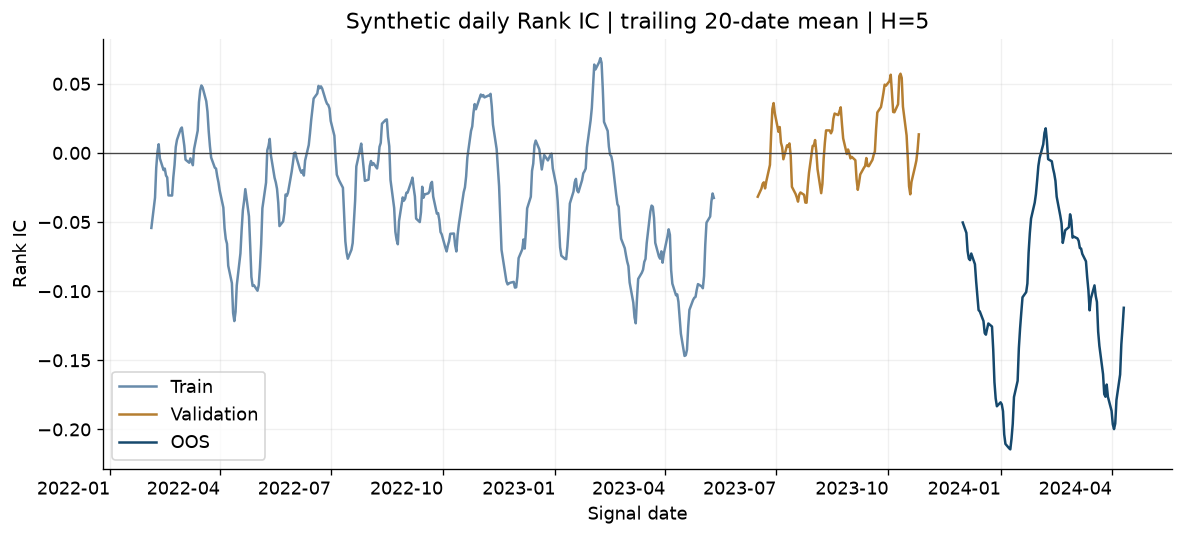

In [7]:
ic_by_split, ic_summaries = {}, []
for name, (start, end) in splits.items():
    dates = sample_dates(sessions, start, end, horizon=H)
    ic_by_split[name] = daily_rank_ic(score, labels, dates, min_assets=10)
    ic_summaries.append({'样本段': name, **summarize_ic(ic_by_split[name])})
display(pd.DataFrame(ic_summaries).round(5))
fig, ax = plt.subplots()
for name, color, label in [('训练','#688baa','Train'),('验证','#b57e31','Validation'),('留出','#16496d','OOS')]:
    values = ic_by_split[name]['rank_ic']
    ax.plot(values.index, values.rolling(20, min_periods=20).mean(), color=color, label=label)
ax.axhline(0, color='#454545', linewidth=0.8)
ax.set(title='Synthetic daily Rank IC | trailing 20-date mean | H=5', ylabel='Rank IC', xlabel='Signal date')
ax.legend(); fig.autofmt_xdate(rotation=0); fig.tight_layout(); plt.show()

**观察：** 本次训练平均 IC 约 −0.0333，验证约 +0.0010，留出约 −0.0928。不同区间并不稳定，留出方向明显与假设相反。这只描述这份固定模拟样本，不可推出真实市场结论。

**练习：** 用 `ic_by_split['留出']['rank_ic']` 手动计算均值、`std(ddof=1)` 和二者比值。解释 IC 为正为何也不保证扣费多头赚钱。

### 7．观察 1/5/10/20 日的信号衰减

这里在留出区间使用**同一组信号日期**，按照最长的 20 日标签统一剔除末尾，因此各持有期都是 99 个日度 IC。否则短持有期多出的一截样本也会影响比较。

**预测：** 假设效应存在且很短暂，平均 IC 随持有期延长可能怎样变化？真实数据是否一定单调？

,horizon,n_dates,mean_rank_ic,std_rank_ic,icir_unannualized,positive_fraction
0,1,99,-0.08583,0.16966,-0.50591,0.27273
1,5,99,-0.09562,0.14430,-0.66268,0.24242
2,10,99,-0.04615,0.12852,-0.35909,0.39394
3,20,99,-0.04375,0.14125,-0.30977,0.35354


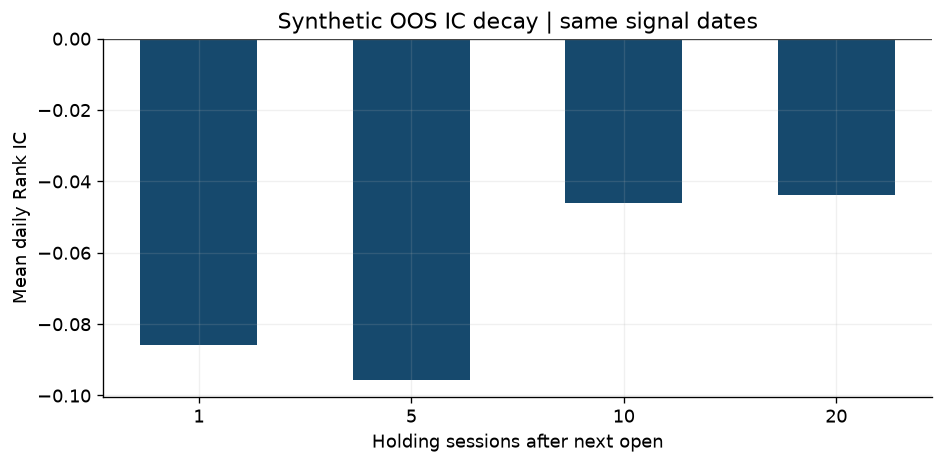

In [8]:
oos_start, oos_end = splits['留出']
common_dates = sample_dates(sessions, oos_start, oos_end, horizon=20)
decay_rows = []
for horizon in [1, 5, 10, 20]:
    ic = daily_rank_ic(score, forward_returns(panel, horizon), common_dates)
    decay_rows.append({'horizon': horizon, **summarize_ic(ic)})
decay = pd.DataFrame(decay_rows)
display(decay.round(5))
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(decay['horizon'].astype(str), decay['mean_rank_ic'], color='#16496d', width=0.55)
ax.axhline(0, color='#454545', linewidth=0.8)
ax.set(title='Synthetic OOS IC decay | same signal dates', xlabel='Holding sessions after next open', ylabel='Mean daily Rank IC')
fig.tight_layout(); plt.show()

**观察：** 四个持有期的平均 IC 本次都为负，不是漂亮的“正向衰减曲线”。5 日 IC 在本表与上一节略不同，是因为这里把共同信号集合缩到 99 日，而上一节使用 114 日。

**练习：** 如果你看完此表改选表现最好的持有期，为什么同一留出区间不再是严格未见样本？

### 8．先分五层，再构造非重叠多头组合

Q1 为最低分，Q5 为最高分，每层内部等权。主线每 5 个交易日调仓，下一开盘买，到再过 5 日的开盘卖或调仓；相邻持有区间首尾相接，没有把每日新信号都叠成满仓。

等权样本基准使用同日所有有效因子股票。它是研究样本的对照，不是真实指数。每条组合都独立扣费。

**预测：** 即使 Q5 的绝对收益为负，它仍可能优于基准吗？必须比较哪些列？

In [9]:
periods, trades = backtest_groups(panel, score, start=oos_start, end=oos_end,
                                  horizon=H, fee_rate=FEE)
q5_periods = periods[periods['portfolio'].eq('Q5')]
display(q5_periods[['signal_date','entry_date','exit_date','n_assets','gross_return','net_return','nav']].head(5).round(6))
assert np.array_equal(q5_periods['exit_date'].iloc[:-1].to_numpy(), q5_periods['entry_date'].iloc[1:].to_numpy())
print('非重叠持有期数：', len(q5_periods))
final_nav = periods.groupby('portfolio')['nav'].last()
display(final_nav.rename('最终净值（初值1）').to_frame().round(6))

,signal_date,entry_date,exit_date,n_assets,gross_return,net_return,nav
4,2023-11-06,2023-11-07,2023-11-14,10,-0.005912,-0.006905,0.993095
10,2023-11-13,2023-11-14,2023-11-21,10,0.010384,0.008750,1.001784
16,2023-11-20,2023-11-21,2023-11-28,10,-0.010103,-0.011699,0.990064
22,2023-11-27,2023-11-28,2023-12-05,10,0.017382,0.015922,1.005828
28,2023-12-04,2023-12-05,2023-12-12,10,-0.000968,-0.002381,1.003433


非重叠持有期数： 23


,最终净值（初值1）
portfolio,
Q1,0.880276
Q2,0.807339
Q3,0.836254
Q4,0.795577
Q5,0.705858
等权样本,0.831876


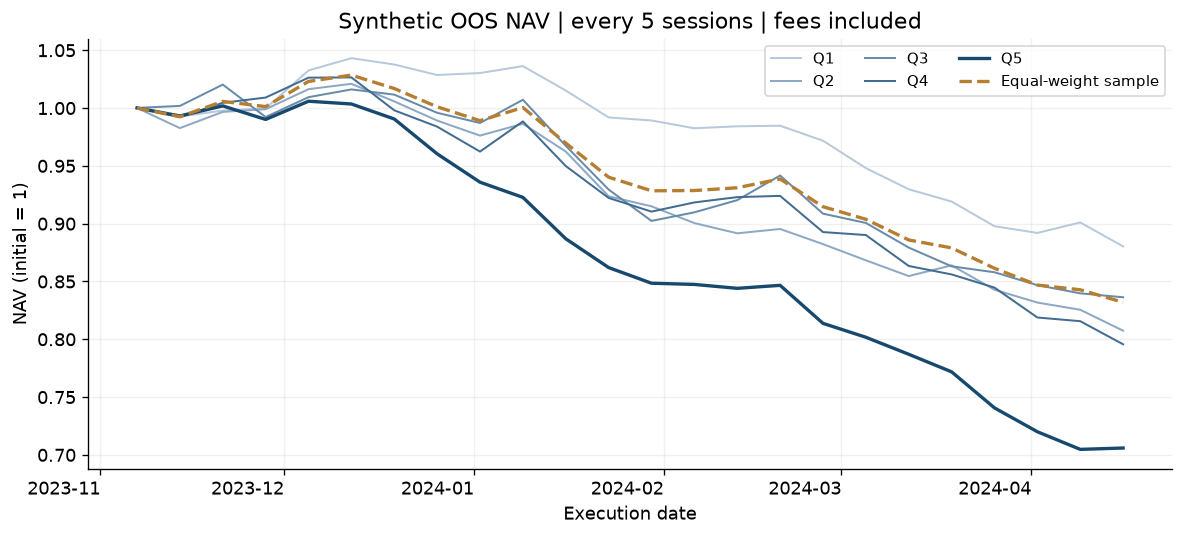

In [10]:
fig, ax = plt.subplots()
colors = {'Q1':'#b8c9db','Q2':'#8da8c5','Q3':'#688baa','Q4':'#426c91','Q5':'#16496d','等权样本':'#b57e31'}
for name in ['Q1','Q2','Q3','Q4','Q5','等权样本']:
    sample = periods[periods['portfolio'].eq(name)]
    ax.plot([sample['entry_date'].iloc[0]]+sample['exit_date'].tolist(), [1.]+sample['nav'].tolist(),
            color=colors[name], label='Equal-weight sample' if name=='等权样本' else name,
            linestyle='--' if name=='等权样本' else '-', linewidth=2 if name in ['Q5','等权样本'] else 1.2)
ax.set(title='Synthetic OOS NAV | every 5 sessions | fees included', ylabel='NAV (initial = 1)', xlabel='Execution date')
ax.legend(ncol=3, fontsize=9); fig.autofmt_xdate(rotation=0); fig.tight_layout(); plt.show()

**观察：** 本次 23 个持有期里，Q5 最终约 0.7059，等权样本约 0.8319；Q5 的绝对表现和相对表现均较差。这里图上的最大回撤只按每 5 日的端点观察，会漏掉持有期内风险，不能当日频最大回撤。

**练习：** 对比每层平均持有期收益，是否单调？如果中间层交错，不能只保留 Q5−Q1 一列就声称分层稳定。

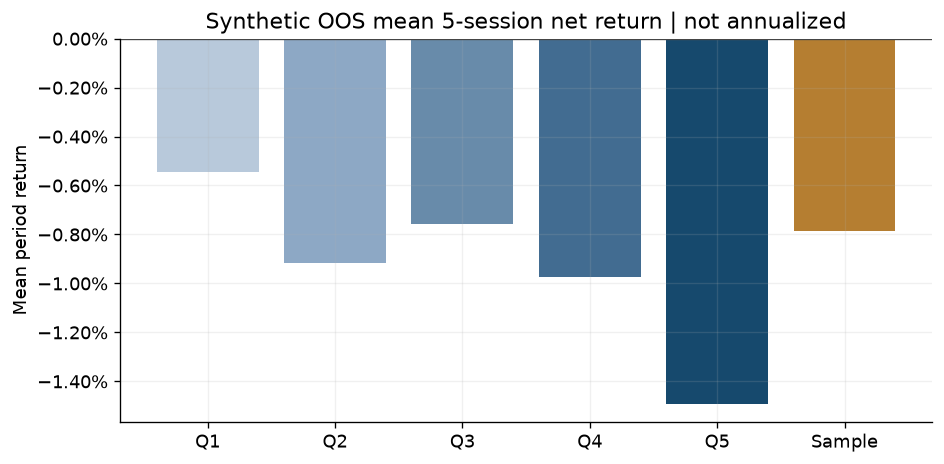

,Q5减Q1毛收益差（仅诊断）
exit_date,
2023-11-14,0.000517
2023-11-21,0.003380
2023-11-28,-0.013447
2023-12-05,-0.016859
2023-12-12,-0.012671


In [11]:
group_mean = periods.groupby('portfolio')['net_return'].mean().reindex(['Q1','Q2','Q3','Q4','Q5','等权样本'])
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(['Q1','Q2','Q3','Q4','Q5','Sample'], group_mean, color=[colors[k] for k in group_mean.index])
ax.axhline(0,color='#454545',linewidth=0.8); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(title='Synthetic OOS mean 5-session net return | not annualized', ylabel='Mean period return')
fig.tight_layout(); plt.show()
gross_wide = periods.pivot(index='exit_date', columns='portfolio', values='gross_return')
display((gross_wide['Q5']-gross_wide['Q1']).rename('Q5减Q1毛收益差（仅诊断）').head(5).to_frame())

**边界：** Q5−Q1 是两个多头分层收益之差，没有借券、保证金或融资费用。这里不把它累计成“可执行多空策略净值”。

### 9．让仓位先漂移，再算真实买卖额

上期甲乙各 50%。甲涨 100%，乙不涨，总资产从 1 变 1.5，调仓前权重变为 2/3 和 1/3。恢复各 50%，应卖甲 1/6、买乙 1/6（相对调仓前资产），买卖总额换手为 1/3；若误拿旧目标比较，会算成零。

费用 = 买卖总成交额 × 单边费率。目标权重占**扣费后**资产，本例精确求解自融资关系：

$$x=1-c\sum_i|xw_i-p_i|.$$

首次建仓也收费；最后平仓也收费。默认 10 基点仅用于教学，不代表真实 A 股统一费率。

**预测：** 从现金买满后马上以相同价格卖光，最终净值是 1，还是略低于 1？

In [12]:
target = pd.Series({'甲':0.5,'乙':0.5})
growth = pd.Series({'甲':2.0,'乙':1.0})
drifted = target*growth/(target*growth).sum()
example_trade = trade_to_target(drifted, target, fee_rate=FEE)
display(pd.DataFrame({'旧目标':target, '漂移后':drifted, '新目标':target}))
display(pd.Series(example_trade, name='精确交易结果').to_frame())
initial = trade_to_target(pd.Series({'甲':0.,'乙':0.}), target, FEE)
final = trade_to_target(target, pd.Series({'甲':0.,'乙':0.}), FEE)
flat_round_trip = initial['remaining_fraction']*final['remaining_fraction']
print(f'零涨跌一次完整买卖：净值={flat_round_trip:.9f}；公式={(1-FEE)/(1+FEE):.9f}')
display(trades[trades['portfolio'].eq('Q5')][['date','event','buy_fraction','sell_fraction','turnover_total','cost_fraction']].iloc[[0,1,2,-1]].round(7))
assert np.isclose(flat_round_trip, (1-FEE)/(1+FEE))

,旧目标,漂移后,新目标
甲,0.5,0.666667,0.5
乙,0.5,0.333333,0.5


,精确交易结果
remaining_fraction,0.999667
buy_fraction,0.166500
sell_fraction,0.166833
turnover_total,0.333333
cost_fraction,0.000333


零涨跌一次完整买卖：净值=0.998001998；公式=0.998001998


,date,event,buy_fraction,sell_fraction,turnover_total,cost_fraction
4,2023-11-07,首次建仓,0.999001,-0.000000,0.999001,0.000999
10,2023-11-14,调仓,0.808158,0.809776,1.617934,0.001618
16,2023-11-21,调仓,0.805644,0.807257,1.612902,0.001613
141,2024-04-16,最后平仓,0.000000,1.000000,1.000000,0.001000


**观察：** `turnover_total` 是买入额加卖出额除以调仓前资产；没有除以 2。最后一期净收益同时包括期初调仓成本与期末清仓成本，表里单列说明。

**练习：** 手算第一次全现金建仓的买入额为何是 $1/(1+c)$，而不是恰好 1。再解释为什么“成交总额费率”和“半换手费率”混用会少算费用。

### 10．解释结果前，先看简单风格暴露

如果 Q5 偏向小市值或少数行业，结果可能反映风格差异。这里只展示一个固定留出信号日，并没有因结果好坏挑日期。

**预测：** 最高分的 10 只模拟股票，其行业权重一定和全样本相同吗？

In [13]:
exposure_date = q5_periods['signal_date'].iloc[0]
group_ids = assign_groups(score.loc[exposure_date])
q5_members = group_ids.index[group_ids.eq(5)]
style = pd.DataFrame({'行业':panel.wide('industry').loc[exposure_date],
                      'log_mv':panel.wide('log_mv').loc[exposure_date]})
industry_weight = pd.concat([style.loc[q5_members,'行业'].value_counts(normalize=True).rename('Q5权重'),
                             style.loc[group_ids.index,'行业'].value_counts(normalize=True).rename('样本权重')],axis=1).fillna(0)
display(industry_weight)
display(pd.Series({'Q5平均log_mv':style.loc[q5_members,'log_mv'].mean(),
                  '样本平均log_mv':style.loc[group_ids.index,'log_mv'].mean()}).to_frame('简单暴露'))
print('这里的行业和规模是模拟字段，不是Barra风险归因。')

,Q5权重,样本权重
行业,,
模拟行业4,0.3,0.2
模拟行业2,0.3,0.2
模拟行业3,0.2,0.2
模拟行业5,0.1,0.2
模拟行业1,0.1,0.2


,简单暴露
Q5平均log_mv,22.903625
样本平均log_mv,22.944074


这里的行业和规模是模拟字段，不是Barra风险归因。


**练习：** 区分“看见暴露”“做中性化”和“证明超额收益”三个命题；每个命题还缺什么证据？

## 核对关键错误

### 11．亲手制造缺失，观察是否跳日

**预测：** 删除 `SIM000` 某个入场日，标签应该留空，还是换成这只股票下一个有记录的开盘？

In [14]:
missing_day = sessions[50]
broken = raw_data[~(raw_data['date'].eq(missing_day) & raw_data['asset'].eq('SIM000'))].copy()
broken_panel = load_panel(broken, sessions=sessions)
broken_labels = forward_returns(broken_panel, H)
prior_signal = sessions[49]
print('缺失网格行数：', broken_panel.quality['missing_grid_rows'])
print('该信号的下一开盘缺失，标签应为空：', broken_labels.loc[prior_signal,'SIM000'])
assert pd.isna(broken_labels.loc[prior_signal,'SIM000'])
print('真实持仓缺交易价时，组合回测会报错停下；需要另建停牌/退市处置规则，不能偷偷删股。')

缺失网格行数： 1
该信号的下一开盘缺失，标签应为空： nan
真实持仓缺交易价时，组合回测会报错停下；需要另建停牌/退市处置规则，不能偷偷删股。


### 12．运行时间对齐与成本测试

测试检查下一开盘、跨股票串线、完整日期网格、未来价格不改过去信号、边界剔除、并列分组、行业规模残差，以及手算漂移换手、首次建仓与末次平仓。

**练习：** 打开 `test_lab.py`，任选一个用例，先描述它防止的业务错误，再读断言。

In [15]:
import subprocess, sys
checked = subprocess.run([sys.executable,'-m','unittest','-v','test_lab.py'], cwd=ROOT, capture_output=True, text=True)
if checked.returncode:
    print(checked.stdout, checked.stderr)
    raise RuntimeError('关键测试失败，请先修复再解读结果。')
print('关键检查：完整测试集通过。')

关键检查：完整测试集通过。


### 13．保存可审计结果

下面用相同固定参数重新生成同目录 CSV、JSON 和 PNG。它保留负结果，不替换数据源，也不扫描“最赚钱参数”。

In [16]:
summary = save_demo_outputs(ROOT)
print('数据：', ROOT/'demo_data')
print('结果：', ROOT/'demo_outputs')
print('结果标签：', summary['data_label'])
print('最终净值：', summary['final_nav_oos'])
assert np.isclose(summary['final_nav_oos']['Q5'], final_nav['Q5'])
output_files = sorted(p.name for p in (ROOT/'demo_outputs').iterdir() if p.is_file())
display(pd.Series(output_files, name='已保存文件').to_frame())

数据： /Users/xuji/Documents/obsidian/股票量化因子研究入门/附件/实验台/demo_data
结果： /Users/xuji/Documents/obsidian/股票量化因子研究入门/附件/实验台/demo_outputs
结果标签： 纯教学模拟；不代表真实 A 股表现
最终净值： {'Q1': 0.8802760249017132, 'Q2': 0.8073392040324073, 'Q3': 0.8362542845334925, 'Q4': 0.7955769583998071, 'Q5': 0.7058580793558257, '等权样本': 0.8318763911320135}


,已保存文件
0,01_oos_nav.png
1,02_rank_ic.png
2,03_ic_decay.png
3,04_group_returns.png
4,daily_ic_by_split.csv
...,...
9,ic_summary.csv
10,portfolio_periods_oos.csv
11,run_summary.json
12,simple_style_exposure_oos.csv


## 下一步：换成真实数据，而不是先换成复杂模型

先保留这个固定假设，依据 `README.md` 的契约接入真实长表和**官方统一交易日历**。不要改动原始模拟 CSV 来假装真实数据。真实接入示意（本格只展示，不会运行下载）：

```python
real_panel = load_panel('real_panel.csv', sessions='exchange_sessions.csv')
real_score = standardize_factor(reversal_factor(real_panel, lookback=5))
```

`adj_factor` 默认必需；确认价格已经复权后，才可显式设 `already_adjusted=True`。没有历史行业或规模就先不做中性化。真实数据还要补齐历史股票池、上市/ST 状态、退市、停牌涨跌停、财报公告时点、成交能力和费用规则。少量股票的接口试跑不能当成全市场研究。

完成本实验的自测题：

1. 不看代码，用三个日期写出本例信号、入场和出场。
2. 解释为什么这份因子的 Q5 代表“过去跌得最多”。
3. 解释每日 H=5 IC 为什么重叠，而主线组合为什么不重叠。
4. 手算甲乙各半、甲翻倍后的换手，指出成本的计费分母。
5. 指出一个会跨训练/验证边界的信号，并说明应当剔除哪一行。
6. 用本次负结果写一段研究结论：明确数据是模拟的、假设未获支持、不能推断真实市场。

这些问题答得清楚以后，再增加一个真实经济假设；先不堆叠机器学习模型。